In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import re
import html
import emoji

from wordcloud import WordCloud
from unidecode import unidecode
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display

## Data import

In [2]:
df = pd.read_csv("./data/dataset.csv")
df.head()

,text_type,text
0,spam,naturally irresistible your corporate identity...
1,spam,the stock trading gunslinger fanny is merrill ...
2,spam,unbelievable new homes made easy im wanting to...
3,spam,4 color printing special request additional in...
4,spam,do not have money get software cds from here s...


## EDA

In [3]:
df.info()
print()
print(df["text_type"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 20348 entries, 0 to 20347
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text_type  20348 non-null  str  
 1   text       20348 non-null  str  
dtypes: str(2)
memory usage: 6.7 MB

<ArrowStringArray>
['spam', 'ham']
Length: 2, dtype: str


In [4]:
print("Null value count:")
print("---------------------")
df.isnull().sum()

Null value count:
---------------------


text_type    0
text         0
dtype: int64

In [5]:
df.shape

(20348, 2)

In [6]:
df.duplicated().sum()

np.int64(14)

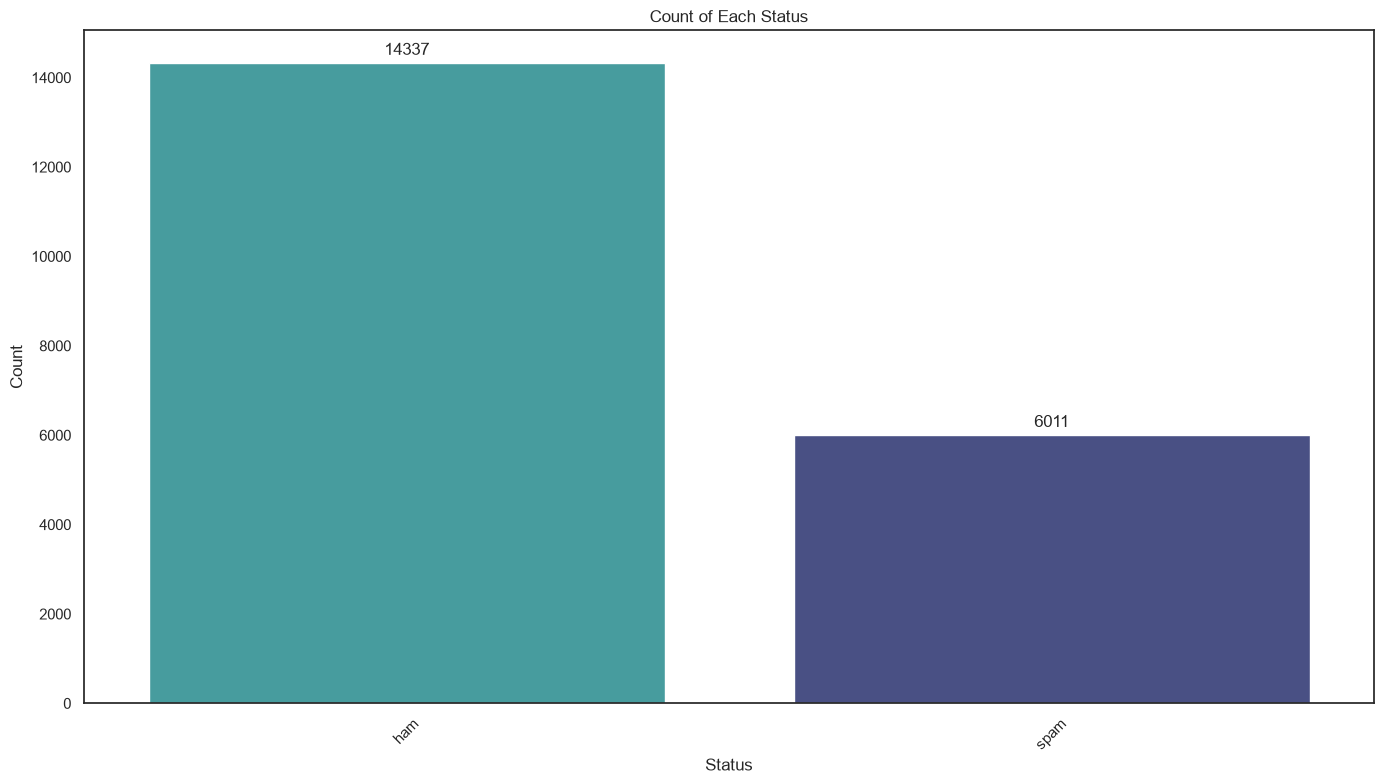

In [7]:
sns.set_theme(style="white")
plt.figure(figsize=(14, 8))

ax = sns.countplot(
    data=df,
    x="text_type",
    order=df["text_type"].value_counts().index,
    palette="mako",
    hue="text_type",
    legend=False
)

# Add exact count labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Count of Each Status")
plt.xlabel("Status")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

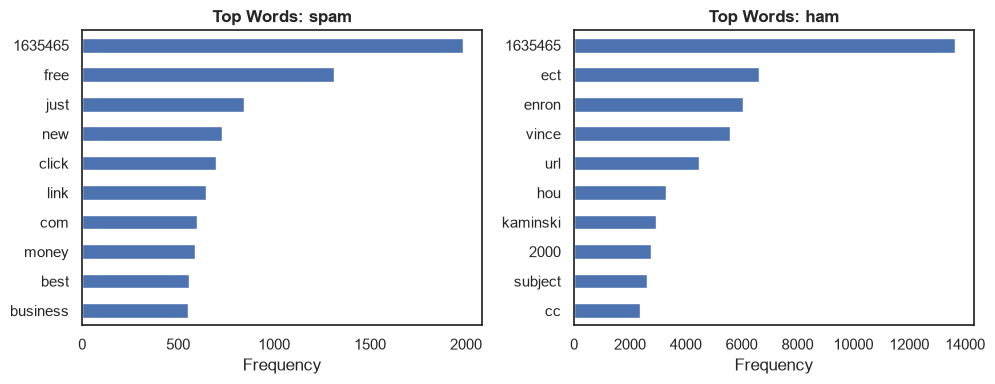

In [8]:
statuses = df["text_type"].dropna().unique()
n_statuses = len(statuses)

n_cols = 2
n_rows = math.ceil(n_statuses / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()  # Flatten 2D grid into 1D array for easy looping

for i, status in enumerate(statuses):
    ax = axes[i]
    statements = df[df["text_type"] == status]["text"].dropna()

    vec = CountVectorizer(stop_words="english", max_features=10)
    bag = vec.fit_transform(statements)

    word_counts = pd.Series(bag.sum(axis=0).A1, index=vec.get_feature_names_out()).sort_values()
    word_counts.plot(kind="barh", ax=ax, color="#4C72B0")

    ax.set_title(f"Top Words: {status}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Frequency")

# Hide any unused empty subplots
for j in range(n_statuses, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

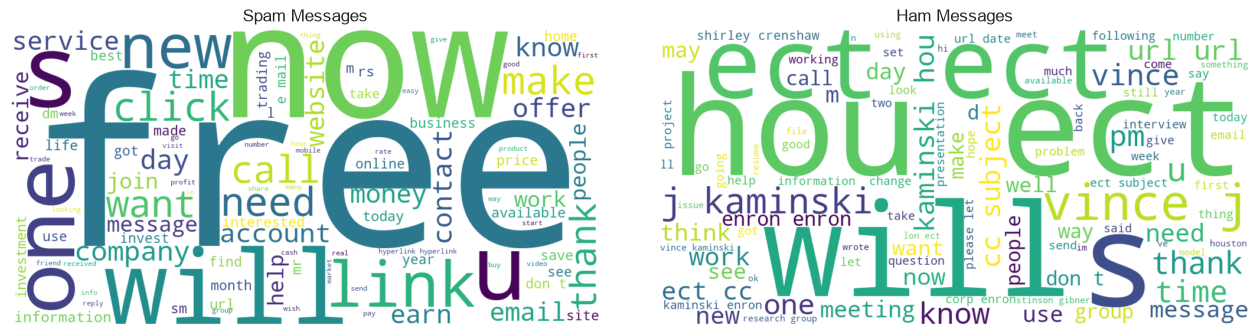

In [9]:
# Combine all spam messages
spam_text = " ".join(
    df[df["text_type"] == "spam"]["text"].astype(str)
)

# Combine all ham messages
ham_text = " ".join(
    df[df["text_type"] == "ham"]["text"].astype(str)
)

# Generate word clouds
spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate(spam_text)

ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate(ham_text)

# Display both word clouds
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(spam_wordcloud, interpolation="bilinear")
axes[0].set_title("Spam Messages", fontsize=12)
axes[0].axis("off")

axes[1].imshow(ham_wordcloud, interpolation="bilinear")
axes[1].set_title("Ham Messages", fontsize=12)
axes[1].axis("off")

plt.subplots_adjust(wspace=0.1)
plt.show()

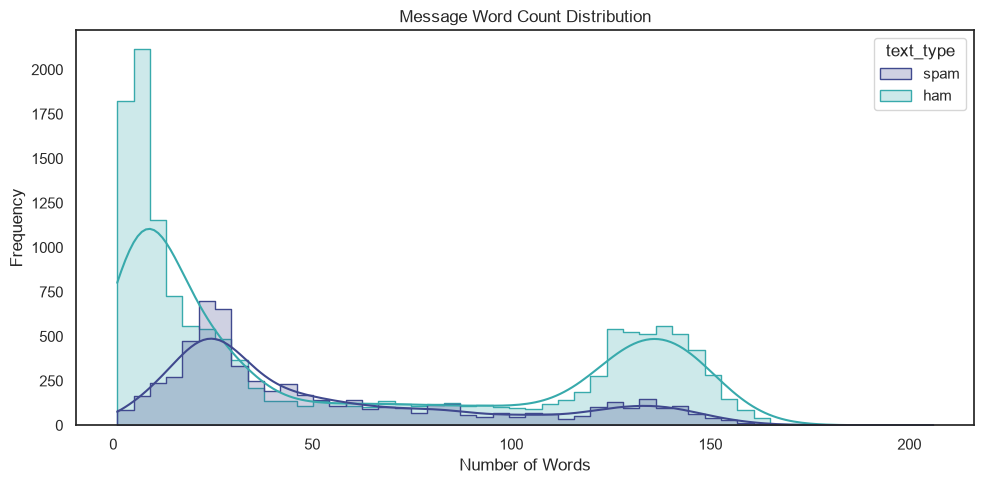

In [10]:
df["word_count"] = df["text"].astype(str).str.split().str.len()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="text_type",
    bins=50,
    kde=True,
    palette="mako",
    element="step"
)

plt.title("Message Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [11]:
for idx, statement in df["text"].sample(5).items():
    print(f"{idx}: {str(statement).strip()}\n")

20182: oh really?

19872: note the setup script

13526: total disappointment when i texted you was the craziest shit got

7264: i wonder if the focus of spambayes ought not to be a classifier that leaves the fetching and feeding of messages to auxillary code that way it could be dropped into whatever harness that suited the user s situation i see no reason to restrict the project to developing the classifier and leave the deployment to others attempts at deployment in the real world will surely provide additional feedback for the classifier guido van rossum home page url

4341: enron image 2000 video is here enron s image 2000 video is now available we think you will like enron s new corporate image video which can be used for employees customers suppliers government officials and other audiences who want to know about enron the video features ken lay jeff skilling and joe sutton who discuss four key business initiatives broadband wholesale energy energy outsourcing services and enrono

In [12]:
idxs = [15191, 19729, 17673]
for idx in idxs:
    print(f"{idx}: {str(df.iloc[idx]["text"]).strip()}\n")

15191: free free free 🥳🥳🎉🎉🎊🎊 🔸free youtube subscribers 🔸free instagram followers 100 guaranted real subscribers/followers safe and secure 🙏🙏🙏 ➖➖➖➖➖➖➖➖➖➖➖➖➖ join channel first 👇 dm me

19729: 𝙸 𝚠𝚊𝚜 𝚕𝚞𝚌𝚔𝚢 𝚎𝚗𝚘𝚞𝚐𝚑 𝚝𝚘 𝚑𝚊𝚟𝚎 @payingnow1 𝚝𝚘 𝚋𝚎 𝚖𝚢 𝚜𝚊𝚟𝚒𝚘𝚞𝚛 𝚠𝚑𝚎𝚛𝚎 𝙸 𝚠𝚊𝚜 𝚒𝚖𝚖𝚎𝚍𝚒𝚊𝚝𝚎𝚕𝚢 𝚒𝚖𝚙𝚛𝚎𝚜𝚜𝚎𝚍 𝚠𝚒𝚝𝚑 𝚑𝚒𝚜 𝚐𝚎𝚗𝚞𝚒𝚗𝚎 𝚊𝚌𝚝 𝚘𝚏 𝚋𝚎𝚒𝚗𝚐 𝚜𝚘 𝚝𝚛𝚞𝚜𝚝𝚠𝚘𝚛𝚝𝚑𝚢 𝚑𝚎 𝚓𝚞𝚜𝚝 𝚜𝚑𝚘𝚠𝚗 𝚖𝚎 𝚝𝚑𝚎 𝚛𝚎𝚊𝚕 𝚖𝚎𝚊𝚗𝚒𝚗𝚐 𝚘𝚏 𝚑𝚞𝚖𝚊𝚗𝚒𝚝𝚢🤗🤗𝙸 𝚗𝚎𝚟𝚎𝚛 𝚔𝚗𝚎𝚠 𝚊𝚗𝚢𝚝𝚑𝚒𝚗𝚐 𝚊𝚋𝚘𝚞𝚝 𝚝𝚛𝚊𝚍𝚒𝚗𝚐 𝚋𝚞𝚝 𝚊𝚏𝚝𝚎𝚛 𝚖𝚎𝚎𝚝𝚒𝚗𝚐 𝚑𝚒𝚖𝚑𝚎 𝚐𝚊𝚟𝚎 𝚖𝚎 𝚍𝚒𝚛𝚎𝚌𝚝𝚒𝚟𝚎𝚜 𝚊𝚗𝚍 𝙸 𝚒𝚗𝚟𝚎𝚜𝚝𝚎𝚍 $350 𝚊𝚗𝚍 𝙸’𝚖 𝚑𝚊𝚙𝚙𝚢 𝙸 𝚐𝚘𝚝 4000$ 𝚒𝚗 12𝚑𝚛𝚜𝚌𝚘𝚗𝚝𝚊𝚌𝚝 𝚑𝚒𝚖 𝚑𝚎’𝚜 𝚝𝚑𝚎 𝚋𝚎𝚜𝚝 👇👇👇👇 👇👇👇👇👇👇 whatsapp 15513331825

17673: 🎬 khaakiyin vettai 2021 ⚜தமிழ் + malayalam watch online or download just install playit app from playstore 🚀 fastest speed no buffering ━━━━━━━━━━━━━━━━━ ➠cʜᴀɴɴᴇʟ @atrstatus ❗️ sʜᴀʀᴇ & sᴜᴘᴘᴏʀᴛ us ❗️



## Data cleaning

### Duplicated row removal

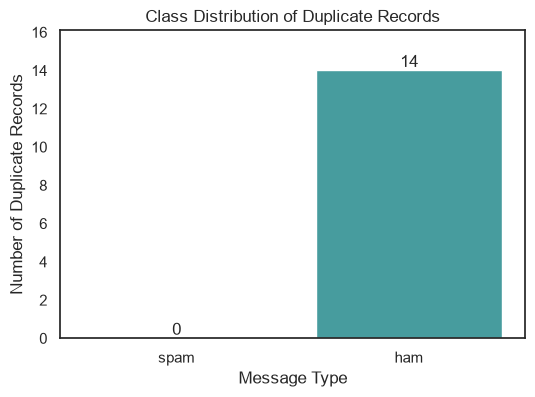

In [13]:
# Extract the 14 additional duplicate records
duplicate_df = df[df.duplicated(keep="first")]

# Ensure both classes are displayed, including zero counts
duplicate_counts = (
    duplicate_df["text_type"]
    .value_counts()
    .reindex(["spam", "ham"], fill_value=0)
)

# Visualise duplicate class distribution
plt.figure(figsize=(6, 4))

ax = sns.barplot(
    x=duplicate_counts.index,
    y=duplicate_counts.values,
    hue=duplicate_counts.index,
    palette="mako",
    legend=False
)

plt.title("Class Distribution of Duplicate Records")
plt.xlabel("Message Type")
plt.ylabel("Number of Duplicate Records")
plt.ylim(0, max(duplicate_counts.max() * 1.15, 1))

# Display count labels
for i, count in enumerate(duplicate_counts.values):
    plt.text(i, count, str(count), ha="center", va="bottom")

plt.show()

In [14]:
df = df.drop_duplicates(subset="text", keep="first")
df.duplicated().sum()

np.int64(0)

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 20334 entries, 0 to 20347
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text_type   20334 non-null  str  
 1   text        20334 non-null  str  
 2   word_count  20334 non-null  int64
dtypes: int64(1), str(2)
memory usage: 7.0 MB


## Text processing

In [16]:
message = df["text"]
label = df["text_type"]

In [17]:
# Convert statement into a consistent inspection format
statement = message.fillna("").astype(str)

# Define patterns to investigate
patterns = {
    "HTML tags": r"<[^>]+>",
    "HTML entities": r"&(?:amp|lt|gt|quot|nbsp|#\d+|#x[0-9a-fA-F]+);",
    "URLs": r"(?:https?://|www\.)\S+",
    "User mentions": r"@\w+",
    "Hashtags": r"#\w+",
    "Zero-width characters": r"[\u200b-\u200f\uFEFF]",
    "Control characters": r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]",
    "Non-ASCII characters": r"[^\x00-\x7F]",
    "Repeated characters (4 or more)": r"(.)\1{3,}",
    "Multiple spaces": r"\s{2,}",
    "Repeated punctuation": r"[!?.,]{3,}",
    "Numbers": r"\d",
    "Possible mojibake": r"(?:Ã.|Â.|â€|ï»¿|ðŸ|ì„|êµ)",
}

# Count the number of rows matching each pattern
results = []
matched_entries = []

for name, pattern in patterns.items():
    matched = statement.str.contains(pattern, regex=True, na=False)

    results.append({
        "Problem / Pattern": name,
        "Rows Found": matched.sum(),
        "Percentage (%)": round(matched.mean() * 100, 2)
    })

    for index, text in statement[matched].head(3).items():

        matched_entries.append({
            "Problem / Pattern": name,
            "Index": index,
        })

audit_df = pd.DataFrame(results)
audit_df = audit_df.sort_values(
    by="Rows Found", ascending=False
)

matched_df = pd.DataFrame(matched_entries)
audit_df

C:\Users\user\AppData\Local\Temp\ipykernel_31248\3385550279.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matched = statement.str.contains(pattern, regex=True, na=False)


,Problem / Pattern,Rows Found,Percentage (%)
11,Numbers,11623,57.16
7,Non-ASCII characters,2548,12.53
8,Repeated characters (4 or more),1242,6.11
3,User mentions,580,2.85
9,Multiple spaces,379,1.86
6,Control characters,106,0.52
10,Repeated punctuation,84,0.41
5,Zero-width characters,36,0.18
2,URLs,1,0.00
4,Hashtags,0,0.00


In [18]:
problems = matched_df["Problem / Pattern"].unique()

for problem in problems:
    idxs = matched_df[matched_df["Problem / Pattern"] == problem]["Index"]
    print(f"=== Sample text of problem: {problem} ===")

    for idx in idxs:
        text = df.loc[idx, "text"]
        print(f"[{idx}] {repr(text)}\n")

=== Sample text of problem: URLs ===
[17429] 'all pubg hack reseller fnàtic mod antibañ hack 100‰✓ main id fnatic cheat officiall https://0 cheap price key dm'

=== Sample text of problem: User mentions ===
[17507] '𝐼 ℎ𝑎𝑣𝑒 𝑡𝑟𝑖𝑒𝑑 𝑠𝑒𝑣𝑒𝑟𝑎𝑙 𝑝𝑙𝑎𝑡𝑓𝑜𝑟𝑚 𝑖𝑡 𝑑𝑖𝑑 𝑛𝑜𝑡 𝑤𝑜𝑟𝑘𝑜𝑢𝑡 𝑏𝑢𝑡 𝑤ℎ𝑒𝑛 𝑖 𝑑𝑖𝑑 𝑡𝑎𝑘𝑒 𝑡ℎ𝑒 𝑟𝑖𝑠𝑘 𝑡𝑜 𝑖𝑛𝑣𝑒𝑠𝑡 $800 𝑖𝑛 𝑙𝑒𝑠𝑠 𝑡ℎ𝑎𝑛 5𝑑𝑎𝑦𝑠 𝑖 𝑔𝑜𝑡 $10000 𝑓𝑟𝑜𝑚 𝑦𝑜𝑢𝑟 𝑝𝑙𝑎𝑡𝑓𝑜𝑟𝑚 𝑖 𝑚𝑢𝑠𝑡 𝑐𝑜𝑛𝑓𝑒𝑠𝑠 𝑦𝑜𝑢 𝑎𝑟𝑒 𝑡𝑟𝑢𝑙𝑦 𝑡ℎ𝑒 𝑏𝑒𝑠𝑡 mrs @dorisbrown click on the link below now👇👇👇👇👇👇👇👇👇👇👇👇 👇👇👇👇👇👇👇👇👇👇👇 @dorisbrown @dorisbrown @dorisbrown @dorisbrown @dorisbrown'

[17509] '🍞💰♿♿ bank pros & logs all usa & uk bank 5050 deal allowed ✅ ☑️ bank logs ☑️ bank pros ☑️ tlo lookups ☑️ unemployment methods and sauces ☑️ccfullz 💰 hmu @richgvng1'

[17518] 'i have benefited so much from his excellent trading technique @geraldarmstrong beginning this journey i started up with $800 within few days i got a return of $7300 his experience and trustworthiness is unmatched'

=== Sample text of problem: Zero-width characters ===
[13614] 'signal is i

In [19]:
def clean_text(text: str, remove_numbers: bool = True,
               remove_repeated_punctuations: bool = True):

    if pd.isna(text):
        return ""

    text = str(text)

    # 1. Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # 2. Decode HTML entities
    text = html.unescape(text)

    # 3. Convert emojis into textual descriptions
    text = emoji.replace_emoji(
        text,
        replace=lambda chars, data: " " + emoji.demojize(chars) + " "
    )

    # 4. Convert Unicode characters into ASCII equivalents
    text = unidecode(text)

    # 5. Remove URLs
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)

    # 6. Remove usernames and mentions
    text = re.sub(r"(?<!\w)@[A-Za-z0-9_]+", " ", text)

    # 7. Remove zero-width characters
    text = re.sub(r"[\u200b-\u200f\ufeff]", "", text)

    # 8. Remove control characters
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", " ", text)

    # 9. Remove decorative symbols while preserving emoji descriptions
    text = re.sub(r"[^\w\s.,!?:]", "", text)

    # 10. Handle numbers
    if remove_numbers:
        text = re.sub(r"\d+", "", text)

    # 11. Reduce repeated characters
    text = re.sub(r"(.)\1{3,}", r"\1\1", text)

    # 12. Reduce repeated punctuation
    if remove_repeated_punctuations:
        text = re.sub(r"[!?.,]{3,}", lambda match: match.group(0)[0], text)

    # 13. Remove specific meaningless number
    text = re.sub(r"\b1635465\b", "", text)

    # 14. Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    # 15. Convert to lowercase
    text = text.lower()

    return text


In [20]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [21]:
stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words -= {'no', 'nor', 'not'}

In [22]:
def get_wordnet_pos(tag):

    if tag.startswith('J'):
        return wordnet.ADJ

    elif tag.startswith('V'):
        return wordnet.VERB

    elif tag.startswith('N'):
        return wordnet.NOUN

    elif tag.startswith('R'):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [23]:
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Tokenization
    tokens = word_tokenize(text)

    # 2. Stopword removal
    tokens = [
        word for word in tokens
        if word.lower() not in stop_words
    ]

    # 3. POS tagging
    pos_tags = nltk.pos_tag(tokens)

    # 4. Lemmatization
    lemmatized_words = []

    for word, tag in pos_tags:

        pos = get_wordnet_pos(tag)

        lemma = lemmatizer.lemmatize(word, pos)

        lemmatized_words.append(lemma)

    return " ".join(lemmatized_words)

In [24]:
cleaned_text  = message.apply(clean_text)
processed_text = cleaned_text.apply(preprocess_text)

In [25]:
# Convert statement into a consistent inspection format
statement = cleaned_text.fillna("").astype(str)

# Define patterns to investigate
patterns = {
    "HTML tags": r"<[^>]+>",
    "HTML entities": r"&(?:amp|lt|gt|quot|nbsp|#\d+|#x[0-9a-fA-F]+);",
    "URLs": r"(?:https?://|www\.)\S+",
    "User mentions": r"@\w+",
    "Hashtags": r"#\w+",
    "Zero-width characters": r"[\u200b-\u200f\uFEFF]",
    "Control characters": r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]",
    "Non-ASCII characters": r"[^\x00-\x7F]",
    "Repeated characters (4 or more)": r"(.)\1{3,}",
    "Multiple spaces": r"\s{2,}",
    "Repeated punctuation": r"[!?.,]{3,}",
    "Numbers": r"\d",
    "Possible mojibake": r"(?:Ã.|Â.|â€|ï»¿|ðŸ|ì„|êµ)",
}

# Count the number of rows matching each pattern
results = []
matched_entries = []

for name, pattern in patterns.items():
    matched = statement.str.contains(pattern, regex=True, na=False)

    results.append({
        "Problem / Pattern": name,
        "Rows Found": matched.sum(),
        "Percentage (%)": round(matched.mean() * 100, 2)
    })

    for index, text in statement[matched].head(3).items():

        matched_entries.append({
            "Problem / Pattern": name,
            "Index": index,
        })

audit_df = pd.DataFrame(results)
audit_df = audit_df.sort_values(
    by="Rows Found", ascending=False
)

matched_df = pd.DataFrame(matched_entries)
audit_df

C:\Users\user\AppData\Local\Temp\ipykernel_31248\916809906.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matched = statement.str.contains(pattern, regex=True, na=False)


,Problem / Pattern,Rows Found,Percentage (%)
0,HTML tags,0,0.0
1,HTML entities,0,0.0
2,URLs,0,0.0
3,User mentions,0,0.0
4,Hashtags,0,0.0
5,Zero-width characters,0,0.0
6,Control characters,0,0.0
7,Non-ASCII characters,0,0.0
8,Repeated characters (4 or more),0,0.0
9,Multiple spaces,0,0.0


## Model development

### Train test split

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    processed_text,
    label,
    test_size=0.2,
    random_state=42,
    stratify=label
)

In [27]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: 16267
Testing samples: 4067

Training label distribution:
text_type
ham     70.437081
spam    29.562919
Name: proportion, dtype: float64

Testing label distribution:
text_type
ham     70.445045
spam    29.554955
Name: proportion, dtype: float64


In [28]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### Vectorization

In [29]:
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    max_features=5000
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

In [30]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [31]:
print("BoW features:", len(bow_vectorizer.get_feature_names_out()))
print("TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))

BoW features: 5000
TF-IDF features: 5000


In [32]:
print("BoW:", bow_vectorizer.get_feature_names_out()[:20])
print("TF-IDF:", tfidf_vectorizer.get_feature_names_out()[:20])

BoW: ['aa' 'aac' 'aap' 'ab' 'ability' 'able' 'able get' 'absence' 'absolutely'
 'abstract' 'abt' 'ac' 'academic' 'accept' 'acceptable' 'access'
 'access request' 'accomplish' 'accord' 'account']
TF-IDF: ['aa' 'aac' 'aap' 'ab' 'ability' 'able' 'able get' 'absence' 'absolutely'
 'abstract' 'abt' 'ac' 'academic' 'accept' 'acceptable' 'access'
 'access request' 'accomplish' 'accord' 'account']


In [33]:
bow_features = bow_vectorizer.get_feature_names_out()

bow_df = pd.DataFrame(
    X_train_bow.toarray(),
    columns=bow_features
)

display(bow_df.iloc[:5, :20])

,aa,aac,aap,ab,ability,able,able get,absence,absolutely,abstract,abt,ac,academic,accept,acceptable,access,access request,accomplish,accord,account
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [34]:
tfidf_features = tfidf_vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    X_train_tfidf.toarray(),
    columns=tfidf_features
)

display(tfidf_df.iloc[:5, :20])

,aa,aac,aap,ab,ability,able,able get,absence,absolutely,abstract,abt,ac,academic,accept,acceptable,access,access request,accomplish,accord,account
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.093507


In [35]:
bow_row = X_train_bow[0].toarray().flatten()
tfidf_row = X_train_tfidf[0].toarray().flatten()

comparison = pd.DataFrame(
    [bow_row, tfidf_row],
    index=["BoW", "TF-IDF"],
    columns=bow_features
)

# Keep only features that appear in the selected message
comparison = comparison.loc[:, comparison.loc["BoW"] > 0]
comparison = comparison.round(2)

display(comparison.iloc[:, :20])

,already,another,cc,cc subject,chance,company,conduct,convenience,corp,corp research,crenshaw,crenshaw hou,day,dear,ect,ect pm,enron,enron corp,forward,forward shirley
BoW,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00,1.00,4.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
TF-IDF,0.07,0.07,0.05,0.06,0.08,0.06,0.1,0.1,0.07,0.11,0.29,0.08,0.05,0.06,0.05,0.07,0.05,0.09,0.06,0.11


In [36]:
models = {
    "BoW + Multinomial NB": (
        MultinomialNB(),
        X_train_bow,
        X_test_bow
    ),

    "BoW + Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        X_train_bow,
        X_test_bow
    ),

    "TF-IDF + Multinomial NB": (
        MultinomialNB(),
        X_train_tfidf,
        X_test_tfidf
    ),

    "TF-IDF + Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        X_train_tfidf,
        X_test_tfidf
    )
}

### Model training

In [37]:
trained_models = {}

for name, (model, X_tr, X_te) in models.items():

    model.fit(X_tr, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

BoW + Multinomial NB trained successfully!
BoW + Logistic Regression trained successfully!
TF-IDF + Multinomial NB trained successfully!
TF-IDF + Logistic Regression trained successfully!



Classification Report: BoW + Multinomial NB
              precision    recall  f1-score   support

         ham       0.97      0.88      0.92      2865
        spam       0.76      0.93      0.84      1202

    accuracy                           0.89      4067
   macro avg       0.87      0.90      0.88      4067
weighted avg       0.91      0.89      0.90      4067



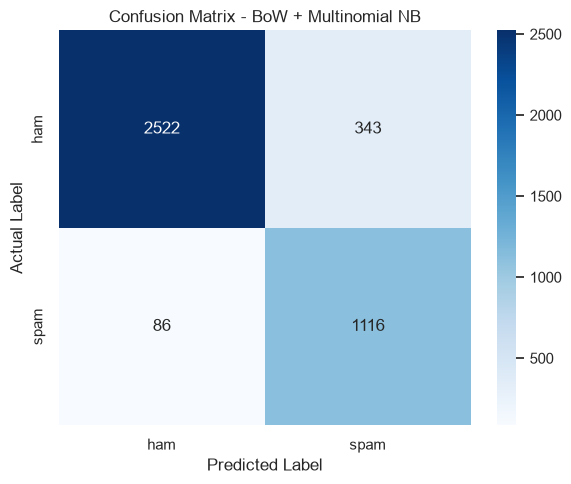


Error Analysis: BoW + Multinomial NB
Total Misclassified Messages: 429

Example 1
Actual Label: ham
Predicted Label: spam
Original Message: my life means a lot to me not because i love my life but because i love the people in my life the world calls them friends i call them my world ge

Example 2
Actual Label: ham
Predicted Label: spam
Original Message: he needs to stop going to bed and make with the fucking dealing

Example 3
Actual Label: ham
Predicted Label: spam
Original Message: i am in 70 loss and chilling 🤣

Classification Report: BoW + Logistic Regression
              precision    recall  f1-score   support

         ham       0.96      0.98      0.97      2865
        spam       0.95      0.90      0.92      1202

    accuracy                           0.96      4067
   macro avg       0.95      0.94      0.95      4067
weighted avg       0.95      0.96      0.95      4067



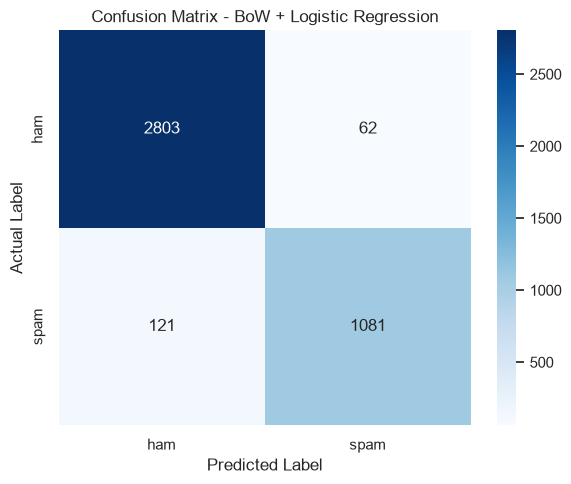


Error Analysis: BoW + Logistic Regression
Total Misclassified Messages: 183

Example 1
Actual Label: spam
Predicted Label: ham
Original Message: i traded with 500 with jans and i got back 5000 in 5 trading days this man has changed many life’s including mine

Example 2
Actual Label: spam
Predicted Label: ham
Original Message: need to find something to be removed from this list click here

Example 3
Actual Label: spam
Predicted Label: ham
Original Message: i do not have anything against you ourref cbn go 0 xol 2 05 date 21 st july 2005 tel 234 1 470 7915 email address mallamyusuf centbanks org dear good friend after a serious thought i decided to reach you directly and personally because i do not have anything against you but your nigerian partners i am the director of wire transfer telex department of the central bank of nigeria some time in the past your nigerian partners approached me through a friend of mine who works with one of the ministries here and requested that i assist them

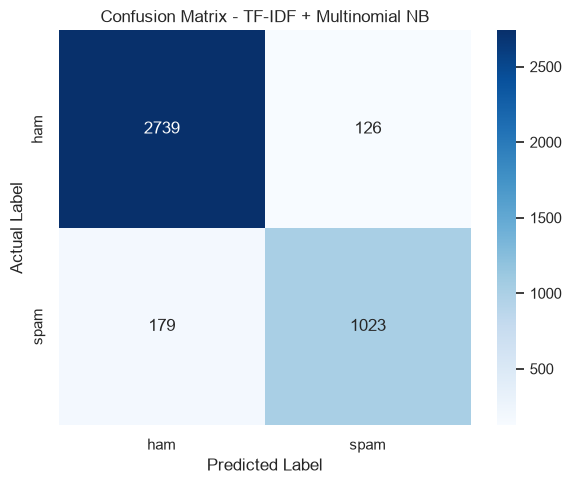


Error Analysis: TF-IDF + Multinomial NB
Total Misclassified Messages: 305

Example 1
Actual Label: spam
Predicted Label: ham
Original Message: i traded with 500 with jans and i got back 5000 in 5 trading days this man has changed many life’s including mine

Example 2
Actual Label: ham
Predicted Label: spam
Original Message: i am in 70 loss and chilling 🤣

Example 3
Actual Label: spam
Predicted Label: ham
Original Message: the database that bill gates doesnt want you to know about if you are struggling with ms access to manage your data don t worry because bill gates agrees that access is confusing if you are finding that ms excel is fine as a spreadsheet but doesn t allow you to build custom applications and reports with your data don t worry there is an alternative the good news is that 1 million customers have found a really good alternativetry our database software that does not make you feel like a dummy for free just email click here to receive your free 30 day full working copy 

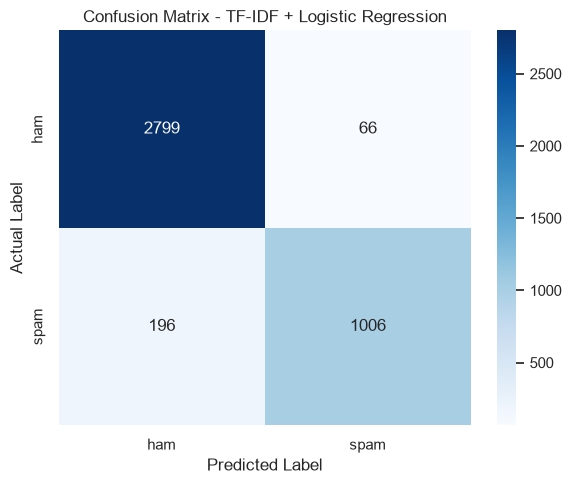


Error Analysis: TF-IDF + Logistic Regression
Total Misclassified Messages: 262

Example 1
Actual Label: spam
Predicted Label: ham
Original Message: i traded with 500 with jans and i got back 5000 in 5 trading days this man has changed many life’s including mine

Example 2
Actual Label: spam
Predicted Label: ham
Original Message: need to find something to be removed from this list click here

Example 3
Actual Label: spam
Predicted Label: ham
Original Message: i do not have anything against you ourref cbn go 0 xol 2 05 date 21 st july 2005 tel 234 1 470 7915 email address mallamyusuf centbanks org dear good friend after a serious thought i decided to reach you directly and personally because i do not have anything against you but your nigerian partners i am the director of wire transfer telex department of the central bank of nigeria some time in the past your nigerian partners approached me through a friend of mine who works with one of the ministries here and requested that i assist t

,Model,Accuracy,Precision,Recall,F1-Score
1,BoW + Logistic Regression,0.9550,0.9458,0.8993,0.9220
3,TF-IDF + Logistic Regression,0.9356,0.9384,0.8369,0.8848
2,TF-IDF + Multinomial NB,0.9250,0.8903,0.8511,0.8703
0,BoW + Multinomial NB,0.8945,0.7649,0.9285,0.8388


In [38]:
results = []

for name, (model, X_tr, X_te) in models.items():

    y_pred = model.predict(X_te)

    # 1. Store evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        )
    })

    # 2. Classification report
    print(f"\n{'='*60}")
    print(f"Classification Report: {name}")
    print(f"{'='*60}")

    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    # 3. Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    # 5. Error analysis
    misclassified_indices = [
        i for i in range(len(y_test))
        if y_test.iloc[i] != y_pred[i]
    ]

    print(f"\n{'='*60}")
    print(f"Error Analysis: {name}")
    print(f"{'='*60}")

    print(f"Total Misclassified Messages: {len(misclassified_indices)}")

    # Display three incorrectly classified examples
    for i, index in enumerate(misclassified_indices[:3], start=1):

        print(f"\nExample {i}")
        print(f"Actual Label: {y_test.iloc[index]}")
        print(f"Predicted Label: {y_pred[index]}")

        # Retrieve the original Telegram message
        original_index = X_test.index[index]
        print(f"Original Message: {df.loc[original_index, 'text']}")


# 4. Overall model comparison
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)

### Prediction on unseen text

In [39]:
unseen_texts = [
    "🚀 VIP Crypto Signals! Join our private channel today and turn $200 into $2,000 in 48 hours with 99% accuracy.",
    "I uploaded the meeting notes to the shared folder. Let me know if anything is missing.",
]

# Step 1: Clean unseen messages
cleaned_unseen = [
    clean_text(t) for t in unseen_texts
]

# Step 2: Apply stopword removal and lemmatization
processed_unseen = [
    preprocess_text(t) for t in cleaned_unseen
]

# Step 3: BoW + Logistic Regression
unseen_bow_vec = bow_vectorizer.transform(processed_unseen)

unseen_bow_pred = trained_models[
    "BoW + Logistic Regression"
].predict(unseen_bow_vec)

# Step 4: TF-IDF + Logistic Regression
unseen_tfidf_vec = tfidf_vectorizer.transform(processed_unseen)

unseen_tfidf_pred = trained_models[
    "TF-IDF + Logistic Regression"
].predict(unseen_tfidf_vec)

# Step 5: Display results
for raw, cleaned, processed, p_bow, p_tfidf in zip(
    unseen_texts,
    cleaned_unseen,
    processed_unseen,
    unseen_bow_pred,
    unseen_tfidf_pred
):
    print(f"\nRaw       : {raw}")
    print(f"Cleaned   : {cleaned}")
    print(f"Processed : {processed}")
    print(f"BoW Pred  : {p_bow}")
    print(f"TF-IDF Pred: {p_tfidf}")


Raw       : 🚀 VIP Crypto Signals! Join our private channel today and turn $200 into $2,000 in 48 hours with 99% accuracy.
Cleaned   : :rocket: vip crypto signals! join our private channel today and turn into , in hours with accuracy.
Processed : : rocket : vip crypto signal ! join private channel today turn , hour accuracy .
BoW Pred  : spam
TF-IDF Pred: spam

Raw       : I uploaded the meeting notes to the shared folder. Let me know if anything is missing.
Cleaned   : i uploaded the meeting notes to the shared folder. let me know if anything is missing.
Processed : uploaded meeting note share folder . let know anything miss .
BoW Pred  : ham
TF-IDF Pred: ham
